[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hbprosper/mlinphysics/blob/main/Labs/07.AE/miniproject_latent_space.ipynb)

# Mini-project: is there structure in the latent space?

> PHY 6937 &mdash; *Machine Learning in Physics* <br>
> Name: <br>
> Date: <br>

## Introduction
A convolutional autoencoder (CAE) is trained to reproduce its input: $\text{encoder} : x \rightarrow z$ followed by $\text{decoder} : z \rightarrow x$. There is no reason *a priori* why a CAE should cluster the input data within the latent space $z \in \mathbb{R}^n$. But to reconstruct $3 \times 96 \times 96 = 27,648$ numbers from just
576 the CAE presumably has discovered *something* about the images of galaxies.

In this mini-project, your task is to find out whether that something is organised into **clusters**,
and whether any clusters you find correspond to the 7 morphology classes into which the galaxy images have been classified by astronomers.

### This is an open-ended project

There is no right or wrong answer for this project. The goal is to explore the latent space and arrive at a conclusion you can justify with evidence.  **"I found no
convincing evidence of clusters"** would be a scientifically legitimate result provided it is justified with evidence.

### Scope

About two class periods. Four short tasks; the setup is done for you.

### Working together

You are **strongly encouraged** to work together: discuss, compare results,
and argue about what they mean. That is how research works. What is unacceptable is handing in code or conclusions you cannot explain.

### Using AI

You may use AI assistants. I use them. But you must document,
in the final cell of this notebook, which tool you used, what you asked it, what you
kept, what you changed, and how you convinced yourself that the answers made sense.

Vague statements such as "I used AI for help" do not count!

---
## Part 0 &mdash; Setup

The cells down to *Part 1* load the trained CAE.

In [1]:
try:
    import google.colab

    REPO = 'hbprosper/mlinphysics'

    url = f"https://raw.githubusercontent.com/{REPO}/refs/heads/main"
    !wget -q {url}/clone2colab.ipynb -O clone2colab.ipynb
    %run clone2colab.ipynb

    IN_COLAB = True

except ImportError:

    IN_COLAB = False

/content
	1. uninstall mlinphysics
	2. sparse clone mlinphysics

/content/mlinphysics
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 5 (delta 0), reused 3 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (5/5), 13.07 KiB | 13.07 MiB/s, done.

	3. install mlinphysics

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content


In [2]:
# standard system modules
import os, sys

# standard module for tabular data
import pandas as pd

# standard module for array manipulation
import numpy as np

# to reimport Python modules
import importlib

# standard module for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt

# standard research-level machine learning toolkit from Meta (FKA: FaceBook)
import torch
import torch.nn as nn
import torch.nn.functional as F

import h5py

# module for shell utilities
import shutil

# ML in physics module
import drwho.nn as mlp
import drwho.data as dat
import drwho.monitor as mon

from tqdm import tqdm

# update fonts
plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "sans-serif",
  "font.size": 14
})

In [3]:
# the tools you will need for this mini-project
from sklearn.cluster  import KMeans
from sklearn.metrics  import silhouette_score, silhouette_samples
from sklearn.metrics  import adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix

In [4]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n\tAvailable device: {str(DEVICE):4s}\n')


	Available device: cuda



### 1. Load image data

In [5]:
#                0, 1, 2, 3
# change shape: (N, C, H, W) => (N, H, C, W) => (N, H, W, C)
def to_images(x):
    images = x.transpose(1,2).transpose(2,3).data.cpu().numpy()
    return images

def load_images(filename='data/galaxy10.h5'):
    with h5py.File(filename, 'r') as F:
        images = np.array(F['images']).astype(np.float32)/256 # normalize pixels
        labels = np.array(F['labels']).astype(np.int64)        # class labels
    return images, labels

def plot_images(images, targets, K=0,
                n_rows=4,
                n_cols=5, filename='galaxies.png',
                title=None):

    f_size = (4, n_rows * 0.8)

    if type(images) == type(torch.Tensor()):
        imgs = to_images(images)
    else:
        imgs = images

    fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=f_size)

    if title is not None:
        fig.suptitle(title)

    # note use of flatten() to convert the matrix
    # of shape (nrows, ncols) to a 1-d array.
    axs = axs.flatten()
    n = len(axs)

    # use "zip" to create an list of shape (N, 3)
    for image, target, ax in zip(imgs[K:K+n], targets[K:K+n], axs):

        ax.axis('off')

        ax.imshow(image)

        # Note: (x, y) coordinates are in pixels,
        # where (0, 0) is the upper left corner
        ax.text(8, 16, f'{target:d}', color='white', fontsize=10)

    plt.savefig(filename)

✅ Download succeeded.
number of images: 12600


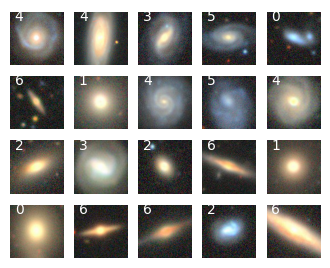

In [6]:
datafile = 'data/galaxy10.h5'

if dat.download(datafile):

    images, targets = load_images(datafile)

    print(f'number of images: {len(images):d}')

    plot_images(images, targets)

else:
    raise RuntimeError(f'''
    Download of file {datafile} failed!
    ''')

### 2. Load configuration

Load the configuration of the trained model.

In [7]:
caefile = 'runs/CAE.tar'

if dat.download(caefile):
    os.system('mkdir -p runs; cd runs; tar xvf CAE.tar')
else:
    raise RuntimeError(f'''
    Download of file {caefile} failed!
    ''')

✅ Download succeeded.


In [8]:
filename = 'runs/CAE/CAE_config.yaml'
config = mlp.Config(filename)
print(config)

name: CAE
file:
  losses: runs/CAE/CAE_losses.csv
  params: runs/CAE/CAE_params.pth
  init_params: runs/CAE/CAE_init_params.pth
  plots: runs/CAE/CAE_plots.png
  config: runs/CAE/CAE_config.yaml
train_size: 10240
test_size: 1400
val_size: 960
batch_size: 256
monitor_step: 100
delete: true
frac: 0.015
n_iterations: 200000
n_steps: 4
n_iters_per_step: 50000
n_epochs: 5000
n_iters_per_epoch: 40
base_lr: 0.001
gamma: 0.8



### 3. Set up test data

In [9]:
train_size = config('train_size')
val_size   = config('val_size')
test_size  = config('test_size')

# change shape ( (N, H, W, C) => (N, C, H, W) )
data = images.transpose(0, 3, 1, 2)

# test dataset
print('test data')
test_data= dat.Dataset(data,
                       start=train_size + val_size,
                       end=train_size + val_size + test_size,
                       targets=targets)

test data
Dataset
  shape of x: torch.Size([1400, 3, 96, 96])
  shape of y: torch.Size([1400])



In [10]:
import torch.utils.data as td
print('test data loader')
test_loader = td.DataLoader(test_data, batch_size=len(test_data))

test data loader


### 4. Define CAE

In [11]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels,
                 activation=nn.ReLU()):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_channels=in_channels,
                      out_channels=out_channels,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            activation,
            nn.MaxPool2d(kernel_size=(2, 2), stride=2)
        )
    def forward(self, x):
        x = self.net(x)
        return x

class ConvTBlock(nn.Module):
    def __init__(self, in_channels, out_channels,
                 activation=nn.ReLU()):
        super().__init__()

        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_channels=in_channels,
                               out_channels=out_channels,
                               kernel_size=2,
                               stride=2),
            activation
        )
    def forward(self, x):
        x = self.net(x)
        return x

class CAutoEncoder(mlp.Model):

    def __init__(self, channels=[3, 6, 12, 24, 16]):
        super().__init__()

        # number of convolutional layers
        nlayers = len(channels)-1

        layers  = [ConvBlock(channels[i], channels[i+1]) for i in range(nlayers)]
        self.encoder = nn.Sequential(*layers)

        channels.reverse()
        layers  = [ConvTBlock(channels[i], channels[i+1]) for i in range(nlayers-1)]
        layers.append( ConvTBlock(channels[-2], channels[-1], activation=nn.Sigmoid()) )
        self. decoder = nn.Sequential(*layers)

    def forward(self, x):
        y = self.encoder(x)
        y = self.decoder(y)
        return y

---
## Part 1 &mdash; The latent space

The encoder turns each $(3, 96, 96)$ galaxy image into a tensor of shape
$(16, 6, 6)$: **16 channels**, each a $6\times6$ map. That is
$16 \times 6 \times 6 = 576$ numbers per galaxy.

Flattened into a single row, each galaxy becomes one point in a
576-dimensional space. The matrix `Z` below has one such row per galaxy, and
`y` holds the morphology label that someone assigned to it. Note, however, that
`y` is not used by the autoencoder. The target is kept so that at the end you can check whether any clusters you found match the morphology classes.

### Initialize latent space tensor `Z`

In [12]:
model = CAutoEncoder().to(DEVICE)
print(model)
print()
print('number of parameters:', mlp.number_of_parameters(model))
print()

# load the best parameters found during training
model.load(config('file/params'))
model.eval()

# the entire test set arrives in a single batch
test_x, test_y = next(iter(test_loader))

with torch.no_grad():
    latent = model.encoder(test_x)

print('latent tensor shape:', tuple(latent.shape), ' <- (N, channels, H, W)')

# Z: one row per galaxy, 576 columns
Z = latent.reshape(len(latent), -1).cpu().numpy()
y = test_y.cpu().numpy()

print('Z.shape =', Z.shape)
print('y.shape =', y.shape)
print('number of morphology classes:', len(np.unique(y)))

CAutoEncoder(
  (encoder): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv2d(3, 6, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv2d(6, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (net): Sequential(
        (0): Conv2d(12, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (3): ConvBlock(
      (net): Sequential(
        (0): Conv2d(24, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dil

---
## Part 2 &mdash; A first look: parallel coordinates

How do you *look* at 576 dimensions? You cannot plot 576 axes at right angles
to each other. One old and rather clever answer is to give up on right angles
and draw the axes **side by side, in parallel**. Each galaxy is then not a
point but a *line*, crossing every axis at its value on that coordinate.

576 parallel axes would still be a solid block of ink. So we compress first:
reduce each channel's $6\times6$ map to a single number, which leaves
**16 numbers per galaxy** &mdash; one per channel. Sixteen axes is readable. Two
reductions are shown below: the channel **mean**, and the channel **maximum**.

Be honest about what this costs: both reductions throw away *where* in the
image each channel responded, and the mean also throws away how strong the
strongest response was. Seeing no structure here would not prove there is none
in the full 576.

Two things to try with the plots below:

- change `N_SHOW` and see how quickly it turns into a hairball
- change the **order** of the axes. The apparent structure changes completely,
  because which lines cross which depends entirely on which axes are adjacent.
  That is a genuine limitation of the method, not a bug.

In [13]:
# shape of latent space
latent.shape

torch.Size([1400, 16, 6, 6])

In [14]:
# flatten tensor starting at dimension 2
# (N, 16, 6, 6) -> (N, 16, 36)
flat = latent.flatten(2)
flat.shape

torch.Size([1400, 16, 36])

In [15]:
# (N, 16, 36) -> (N, 16)

C_avg = flat.mean(dim=2).cpu().numpy()
C_max = flat.max(dim=2).values.cpu().numpy()

print('C_avg.shape =', C_avg.shape)
print('C_max.shape =', C_max.shape)

C_avg.shape = (1400, 16)
C_max.shape = (1400, 16)


In [16]:
N_SHOW = 300                      # how many galaxies to draw

ORDER  = np.arange(C_avg.shape[1])

ORDER

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

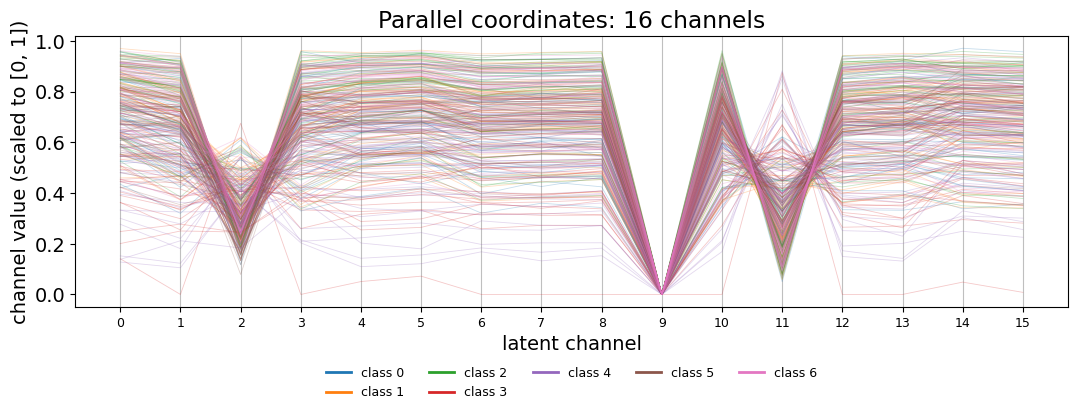

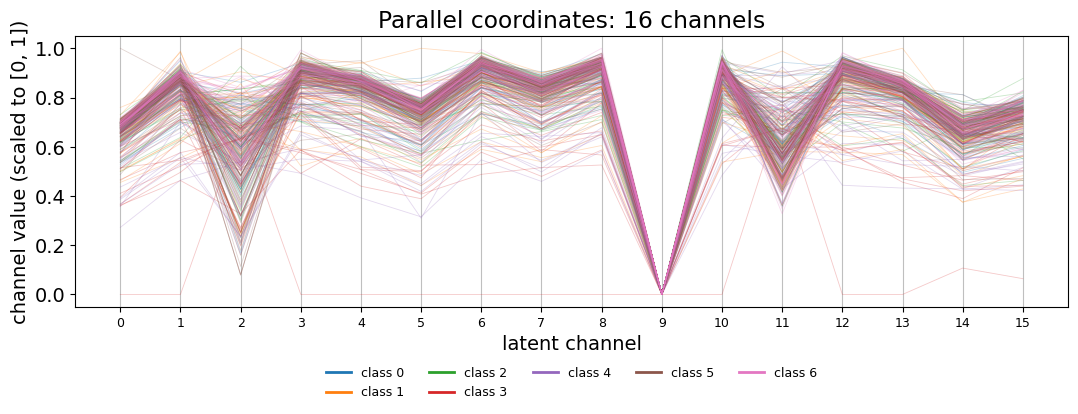

In [17]:
def parallel_coordinates(C, y, order, n_show=300, filename=None):

    A = C[:, order]

    # scale every axis to [0, 1] so that they are comparable
    lo, hi = A.min(axis=0), A.max(axis=0)
    A = (A - lo) / np.where(hi - lo == 0, 1, hi - lo)

    classes = np.unique(y)
    cmap    = plt.get_cmap('tab10')
    x       = np.arange(A.shape[1])

    fig, ax = plt.subplots(figsize=(11, 4.5))

    for k, c in enumerate(classes):
        rows = np.where(y == c)[0][:max(1, n_show // len(classes))]
        for r in rows:
            ax.plot(x, A[r], color=cmap(k % 10), lw=0.6, alpha=0.25)
        # one opaque line per class, for the legend
        ax.plot([], [], color=cmap(k % 10), lw=2, label=f'class {c}')

    for xi in x:
        ax.axvline(xi, color='0.75', lw=0.8, zorder=0)

    ax.set_xticks(x)
    ax.set_xticklabels([str(o) for o in order], fontsize=9)
    ax.set_xlabel('latent channel')
    ax.set_ylabel('channel value (scaled to [0, 1])')
    ax.set_title('Parallel coordinates: 16 channels')
    ax.legend(ncol=5, fontsize=9, frameon=False,
              loc='upper center', bbox_to_anchor=(0.5, -0.18))
    fig.tight_layout()
    if filename:
        plt.savefig(filename)
    plt.show()

parallel_coordinates(C_avg, y, ORDER, n_show=N_SHOW)
parallel_coordinates(C_max, y, ORDER, n_show=N_SHOW)

---
## Part 3 &mdash; Three things you need to understand first

Read this part. The tasks will not make sense otherwise.

### 3.1 The silhouette score: how well separated are the clusters?

Suppose a clustering algorithm has assigned every galaxy to a group. For a given
galaxy $i$, define

- $a(i)$ &mdash; the average distance from $i$ to the **other galaxies in its
  own cluster**. A small value means $i$ sits comfortably among its neighbors.
- $b(i)$ &mdash; the average distance from $i$ to the galaxies in the
  **nearest other cluster**. A large value means the next group is far away.

The **silhouette** of galaxy $i$ is

$$ s(i) \; = \; \frac{b(i) - a(i)}{\max\!\big(a(i),\, b(i)\big)} , $$

which lies between $-1$ and $+1$:

| $s(i)$ | meaning |
| :--- | :--- |
| near $+1$ | well inside its own cluster, far from any other |
| near $0$ | on the boundary between two clusters |
| negative | closer to a different cluster &mdash; probably assigned to the wrong one |

The **silhouette score** of a whole clustering is the average of $s(i)$ over
all galaxies. Higher is better separated.

`sklearn.metrics.silhouette_score(Z, labels)` computes it.
`sklearn.metrics.silhouette_samples(Z, labels)` returns the individual
$s(i)$ instead of their mean. You will want those in Task 2.

Now the catch, and it is the important part:

> **The silhouette score always returns a number.** Hand it pure noise and it
> will cheerfully report a positive score, because any finite random sample has
> accidental thin patches and dense patches, and a clustering algorithm will
> find them. A positive silhouette score, *on its own*, is not evidence of
> anything.

**A warning about the size of the number.** In 576 dimensions, distances
between points all become rather similar &mdash; everything is far from
everything else, and roughly equally so. The practical consequence is that
silhouette scores come out *small* even when the clustering is perfect. On
synthetic data with five clean, well-separated groups in 576 dimensions,
k-means recovered the groups exactly and the silhouette score was still only
about $0.06$.

So do not judge your result by whether the number looks impressive. A
silhouette of $0.05$ may be meaningful here and a silhouette of $0.3$ may not
be. Judge it by the comparison in the next section.


### 3.2 Why you must shuffle: building a null

A clustering algorithm does not answer the question "are there clusters?" If you ask `KMeans` for 4 clusters, it will return 4 clusters &mdash; come what may! The algorithm has no way
to say "there is nothing here". The algorithm is **constructive**, not **inferential**.

To create an inferential algorithm based on the scores that answers the question do clusters exist, we need the probability density of scores computed for a point cloud where we know *a priori* that no clusters are present. This distribution is called the **null distribution**. Here we are using the same logic from data analysis in physics and other quantitative fields. One can never claim that a signal has been detected with some level of confidence until one knows what scores are to be expected in the absence of a signal.

#### How to remove potential structure without changing anything else

Take the matrix `Z`, which has one row per galaxy and $n = 576$ columns. Denote the probability density of these data as $p(Z) \equiv p(z_0, z_1, \cdots, z_{n-1})$.  Now
**shuffle each column independently**.

Think about what this does and does not change:

- Every column keeps **exactly** the same set of values, so each
  latent coordinate has the same distribution, $p(z_i) = \int p(Z) \, \prod_{j \ne i} dz_j$, as before, which can be approximated with a histogram.
- But the statistical dependencies between columns, that is, between latent variables have been **destroyed**. We have forced the coordinates of each row to vary independently of one another, hence no genuine clusters. Clusters will be found; but they won't be statistically meaningful. This is reflected in the fact that the density of the new point cloud will have the factorized form
$q(Z) \equiv p(z_0) \, p(z_1) \cdots p(z_{n-1})$.
By definition, a cluster is a group of rows whose latent variables vary in some coordinated way that goes well beyond what is expected by chance.

So the shuffled matrix is your data **minus potential structure**.

#### What you do with it

Run your *entire* clustering procedure on the shuffled matrix, exactly as you
did on the real one. For different numbers, $k$, of specified clusters, plot the distributions of the silhouette scores for both the original and shuffled point clouds in the latent space. If the two distributions always fully overlap then, alas, whatever `KMeans` is returning, it is not a set of meaningful clusters. On the other hand, if there is a measurable separation between the null and the **alternative** distributions, determine for which $k$ the separation is most marked.

Shuffle a few times with different random seeds, so you can see how much the
null distributions wobble.

### 3.3 Comparing with the labels: contingency tables and the adjusted Rand index

Suppose you end up with $k = 5$ clusters but the data has 7 classes. How do
you compare them? Well, not by checking whether cluster numbers equal class numbers! These labels are arbitrary. You need a way to compare groups that does not depend on the labels assigned to classes and clusters.

#### The contingency table

Make a table with one **row per cluster** and one **column per class**, where
each entry counts the galaxies that are in that cluster *and* that class.
(`sklearn.metrics.cluster.contingency_matrix`, or `pandas.crosstab`.)

Then read it:

- a row with one big entry and the rest near zero means that cluster
  corresponds to a single morphology class
- a row spread evenly across all columns means that cluster is a mixture and
  corresponds to nothing in the catalog
- a column spread across many rows means that class was split up by the
  clustering

Drawing it as a heatmap makes this readable at a glance.

#### The adjusted Rand index

The table shows you *what* the correspondence is; the adjusted Rand index
reduces it to a single number saying *how strong* it is.

It works on **pairs** of galaxies. For every pair, ask: do the two partitions
agree about them? They agree if both put the pair in the same group, or if
both put them in different groups. The Rand index is the fraction of pairs on
which they agree.

The problem with the raw Rand index is that two completely random partitions
still agree about a great many pairs purely by chance. The **adjusted** Rand
index subtracts off that chance expectation and rescales, so that

| ARI | meaning |
| :--- | :--- |
| $1$ | the two partitions are identical |
| $0$ | exactly what you would expect from random labelling |
| $< 0$ | agreement *worse* than chance |

It does not care how you numbered your clusters, and it does not require the
number of clusters to equal the number of classes.

`sklearn.metrics.adjusted_rand_score(y, labels)`.

---
# <span style="color:#b03a2e">Your work starts here</span>

Four tasks. Add as many cells as you need under each.

### Task 1 &mdash; Cluster, and choose a number

Run `KMeans` on `Z` for $k = 2, 3, \ldots, 10$. For each $k$, record the
silhouette score. Plot score against $k$.

Which $k$ would you choose, and why? Is the choice obvious or marginal?

*(Fix `random_state` so your results are reproducible.)*

In [18]:
# Task 1
list = [2,3,4,5,6,7,8,9,10]
scores = []
k_values = []

for k in list:

    #calculate the kMean for each of the number of clusters we want
    kmean = KMeans(n_clusters=k, random_state=42)
    labels = kmean.fit_predict(Z)

    #then we want the s(i) score for that
    score = silhouette_score(Z, labels)

    #print out the answer
    print(f"k = {k}, silhouette = {score:.4f}")

    #for plotting later
    scores.append(score)
    k_values.append(k)

k = 2, silhouette = 0.3694
k = 3, silhouette = 0.2414
k = 4, silhouette = 0.1770
k = 5, silhouette = 0.1358
k = 6, silhouette = 0.1221
k = 7, silhouette = 0.1105
k = 8, silhouette = 0.1302
k = 9, silhouette = 0.1150
k = 10, silhouette = 0.1158


I would choose the k = 2 due to the fact that it has the highest silhouette number. I think it's obvious against some of the choices such as k = 6,9,10 but values such as k = 3 and 4 are not much smaller. Theres also a question of it's not clear how much a score of 0.1358 is better than 0.1221, it might be but it might not be. It's not a tell all for how well things are clustered.

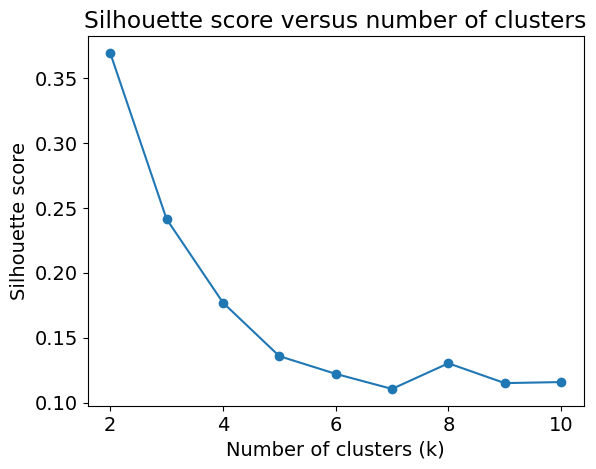

In [19]:
plt.plot(k_values, scores, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score versus number of clusters')
plt.show()

### Task 2 &mdash; Is it real?

Build the shuffled null described in 3.2: copy `Z`, permute each column
independently, and run **exactly** the same loop over $k$ on the shuffled
copy. Repeat for a few different random seeds.

Plot the real curve and the null curves on the same axes.

Now for the distributions that &sect;3.2 asks for. The silhouette *score* is
only the **mean** of the per-galaxy values $s(i)$ defined in &sect;3.1, and
`silhouette_samples` hands back all 1400 of them. So pick a $k$ and histogram
the $s(i)$ for the real `Z` and for a shuffled copy on the same axes. A log
scale on the vertical axis helps.

Two cautions before you read anything off it.

- After shuffling, row $i$ is a chimera: coordinate 0 from one galaxy,
  coordinate 1 from another. There is no "galaxy $i$ under the null" to compare
  galaxy $i$ against. So the comparison is each real $s(i)$ against the
  **pooled** set of null values, not against a matching null galaxy.
- The $s(i)$ are not independent of one another &mdash; they share one
  clustering and one set of centroids. A count of "significant" galaxies
  therefore describes where the two histograms sit relative to each other. It is
  not 1400 independent experiments.

With that in hand you can ask the question one galaxy at a time: what fraction
of the null values exceed this galaxy's $s(i)$? Do it, and then think hard about
the answer. If almost every galaxy in the sample clears the null, is that what a
cluster structure ought to look like? What would you expect $s(i)$ to do for a
galaxy at the core of a cluster, compared with one on its boundary?

What do you conclude? Be specific about what in the figure supports it.

In [20]:
Z.shape
#Z[:, 0]    coordinate 0 across all galaxies
#Z[0, :]    all 576 coordinates for galaxy 0

(1400, 576)

In [21]:
# Task 2
Z_copy = Z.copy()
rng = np.random.default_rng(42)

i = 0
while (i <= 575):
  Z_copy[:,i] = rng.permutation(Z_copy[:,i])
  i = i + 1

In [22]:
Z_copy_20 = Z.copy()
rng = np.random.default_rng(20)

i = 0
while (i <= 575):
  Z_copy_20[:,i] = rng.permutation(Z_copy_20[:,i])
  i = i + 1

In [23]:
Z_copy_30 = Z.copy()
rng = np.random.default_rng(30)

i = 0
while (i <= 575):
  Z_copy_30[:,i] = rng.permutation(Z_copy_30[:,i])
  i = i + 1

In [24]:
scores_copy = []
k_values_copy = []

for k in list:

    #calculate the kMean for each of the number of clusters we want
    kmean = KMeans(n_clusters=k, random_state=42)
    labels = kmean.fit_predict(Z_copy)

    #then we want the s(i) score for that
    score = silhouette_score(Z_copy, labels)

    #print out the answer
    print(f"k = {k}, silhouette = {score:.4f}")

    #for plotting later
    scores_copy.append(score)
    k_values_copy.append(k)

k = 2, silhouette = 0.0034
k = 3, silhouette = 0.0019
k = 4, silhouette = 0.0025
k = 5, silhouette = 0.0023
k = 6, silhouette = 0.0013
k = 7, silhouette = 0.0014
k = 8, silhouette = 0.0021
k = 9, silhouette = 0.0019
k = 10, silhouette = 0.0016


In [67]:
scores_copy_20 = []
k_values_copy_20 = []

for k in list:

    #calculate the kMean for each of the number of clusters we want
    kmean = KMeans(n_clusters=k, random_state=42)
    labels = kmean.fit_predict(Z_copy_20)

    #then we want the s(i) score for that
    score = silhouette_score(Z_copy_20, labels)

    #print out the answer
    print(f"k = {k}, silhouette = {score:.4f}")

    #for plotting later
    scores_copy_20.append(score)
    k_values_copy_20.append(k)

k = 2, silhouette = 0.0038
k = 3, silhouette = -0.0004
k = 4, silhouette = 0.0013
k = 5, silhouette = 0.0011
k = 6, silhouette = 0.0013
k = 7, silhouette = 0.0012
k = 8, silhouette = -0.0024
k = 9, silhouette = -0.0005
k = 10, silhouette = -0.0001


In [68]:
scores_copy_30 = []
k_values_copy_30 = []

for k in list:

    #calculate the kMean for each of the number of clusters we want
    kmean = KMeans(n_clusters=k, random_state=42)
    labels = kmean.fit_predict(Z_copy_30)

    #then we want the s(i) score for that
    score = silhouette_score(Z_copy_30, labels)

    #print out the answer
    print(f"k = {k}, silhouette = {score:.4f}")

    #for plotting later
    scores_copy_30.append(score)
    k_values_copy_30.append(k)

k = 2, silhouette = 0.0031
k = 3, silhouette = 0.0029
k = 4, silhouette = 0.0030
k = 5, silhouette = 0.0021
k = 6, silhouette = 0.0021
k = 7, silhouette = 0.0020
k = 8, silhouette = 0.0018
k = 9, silhouette = -0.0008
k = 10, silhouette = -0.0005


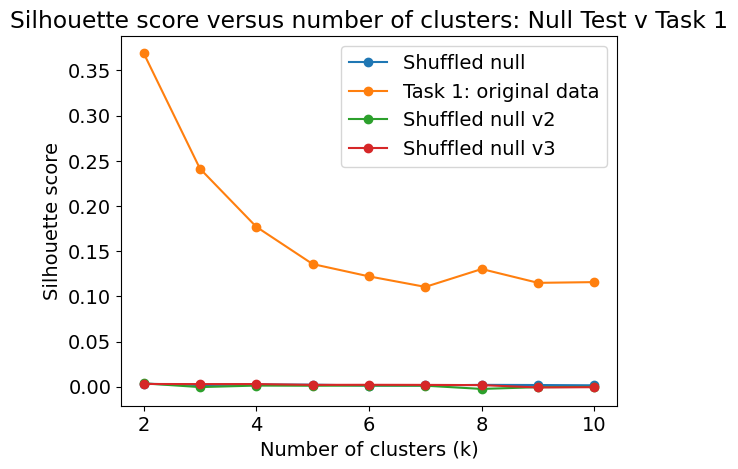

In [69]:
plt.plot(k_values_copy,scores_copy, marker='o', label='Shuffled null')
plt.plot(k_values,scores, marker='o', label='Task 1: original data')
plt.plot(k_values_copy_20, scores_copy_20, marker = 'o', label='Shuffled null v2' )
plt.plot(k_values_copy_30, scores_copy_30, marker = 'o', label='Shuffled null v3' )
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score versus number of clusters: Null Test v Task 1')
plt.legend()
plt.show()

In [70]:
#choosing my k
k_picked = 2

kmean_picked = KMeans(n_clusters=k_picked, random_state=42)
labels_picked = kmean_picked.fit_predict(Z)
labels_picked_copy = kmean_picked.fit_predict(Z_copy)

sample = silhouette_samples(Z,labels_picked)
sample_copy = silhouette_samples(Z_copy,labels_picked_copy)

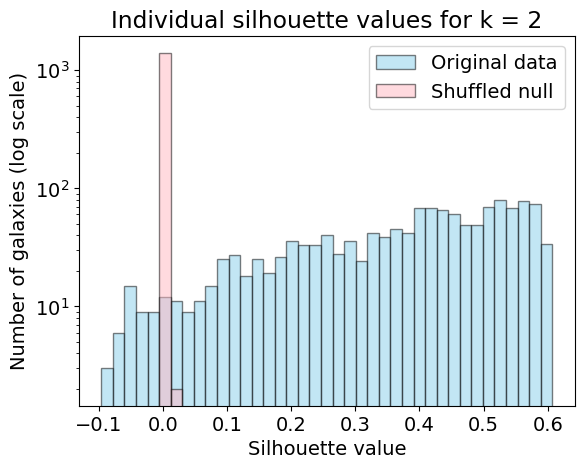

In [71]:
# Use the same bin boundaries for both histograms
bins = np.linspace(min(sample.min(), sample_copy.min()),max(sample.max(), sample_copy.max()),40)

plt.hist(sample, bins=bins, alpha=0.5, color='skyblue', edgecolor='black', label='Original data')

plt.hist(sample_copy, bins=bins, alpha=0.5, color='lightpink', edgecolor='black', label='Shuffled null')

plt.xlabel('Silhouette value')
plt.ylabel('Number of galaxies (log scale)')
plt.title('Individual silhouette values for k = 2')
plt.yscale('log')
plt.legend()
plt.show()

In [72]:
#sample -> one sihoulette value per real galaxy, measuring how well it fits its assigned cluster
#sample_copy -> same measurement but for the shuffled data

#sihoulette value of the first galaxy out of the 1400 possible
s_first = sample[0]
#Then this is producing 1400 true or false values. Averaging those where
#True is 1 and False is 0
fraction = np.mean(sample_copy > s_first)

print("Galaxy's silhouette:", s_first)
print("Fraction of null values exceeding it:", fraction)

Galaxy's silhouette: 0.011450764
Fraction of null values exceeding it: 0.004285714285714286


In [73]:
fractions = []

for i in sample:
  fraction = np.mean(sample_copy> i)
  fractions.append(fraction)

In [74]:
for i in range(20):
    print(f"Galaxy {i}: silhouette = {sample[i]:.4f}, "
          f"fraction of nulls exceeding it = {fractions[i]:.4f}")

Galaxy 0: silhouette = 0.0115, fraction of nulls exceeding it = 0.0043
Galaxy 1: silhouette = 0.4185, fraction of nulls exceeding it = 0.0000
Galaxy 2: silhouette = 0.5791, fraction of nulls exceeding it = 0.0000
Galaxy 3: silhouette = 0.4707, fraction of nulls exceeding it = 0.0000
Galaxy 4: silhouette = 0.5644, fraction of nulls exceeding it = 0.0000
Galaxy 5: silhouette = 0.4626, fraction of nulls exceeding it = 0.0000
Galaxy 6: silhouette = 0.4482, fraction of nulls exceeding it = 0.0000
Galaxy 7: silhouette = 0.6069, fraction of nulls exceeding it = 0.0000
Galaxy 8: silhouette = 0.3282, fraction of nulls exceeding it = 0.0000
Galaxy 9: silhouette = -0.0348, fraction of nulls exceeding it = 1.0000
Galaxy 10: silhouette = 0.5485, fraction of nulls exceeding it = 0.0000
Galaxy 11: silhouette = 0.4625, fraction of nulls exceeding it = 0.0000
Galaxy 12: silhouette = 0.5982, fraction of nulls exceeding it = 0.0000
Galaxy 13: silhouette = 0.1869, fraction of nulls exceeding it = 0.0000
G

These examples show that a galaxy that has a silhouette value that exceeds the null values doesn't mean it's necesarily a strong fit to its assigned cluster. Looking at galaxy 0, it doesnt have a great silhouette score but it has a better one than most of the shuffled data.
As for the silhouette scores, one close to one means its probably closer to the center of the cluster versus a score closer to zero means it's most likeley further out towards the edge. Maybe close to the boundary of the other cluster.

In [75]:
#Generated by GPT
#this code takes the list of fractions and converts it into a numpy array so
#all calculations can be done at once

#so you're asking for each galaxy did fewer than 5% of the shuffled values
#exceed the silhouette because like above that gives back a true/false statement
#True is 1 and False is 0 and you take the average of those 1400 numbers

#so this value says that 96% of real galaxies had silhouettes higher than roughly
#95% of the shuffled values

fractions = np.asarray(fractions)
print(np.mean(fractions < 0.05))

0.9664285714285714


### Task 3 &mdash; Do the clusters correspond to the labels?

For the $k$ you chose in Task 1, build the contingency table of cluster versus
morphology class, draw it as a heatmap, and compute the adjusted Rand index.

Does any individual cluster line up with a class, even if the overall ARI is
small? Which classes get split or merged?

One extra line of code is worth running here. Treat the true labels `y` as if
they were a clustering and compute `silhouette_score(Z, y)`. Before you run it,
decide what you expect; afterwards, work out what the value you got implies
about whether *any* clustering algorithm, with any $k$, could have recovered the
morphology classes from this latent space.

In [57]:
#Task 3
table = pd.crosstab( labels_picked, y, rownames=['Cluster'], colnames= ['Morphooogy class'])
print(table)

Morphooogy class    0    1    2    3    4    5    6
Cluster                                            
0                 121  175  179   93   75  124  167
1                  76   46   27  113  121   59   24


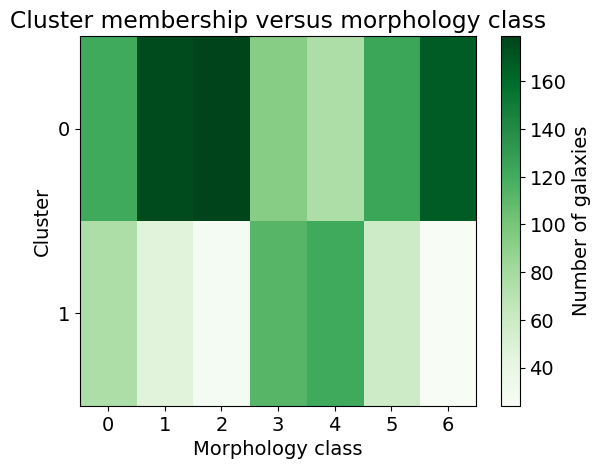

In [62]:
# Display the table counts as colored cells.
# Darker green means more galaxies; 'auto' lets cells stretch to fit.
plt.imshow(table, cmap='Greens', aspect='auto')

# Show how colors correspond to galaxy counts.
plt.colorbar(label='Number of galaxies')

# Place a tick at each column and label it with its morphology class.
plt.xticks(range(len(table.columns)), table.columns)

# Place a tick at each row and label it with its cluster number.
plt.yticks(range(len(table.index)), table.index)

# Label the axes and give the plot a title.
plt.xlabel('Morphology class')
plt.ylabel('Cluster')
plt.title('Cluster membership versus morphology class')

# Display the completed plot.
plt.show()

In [64]:
ARI = adjusted_rand_score(y, labels_picked)
print(ARI)

0.03453301051361884


I only have two clusters so it's hard to say with these but it looks as if class 1, 2 and 6 really fit well with cluster 0 but nearly every other morphology class is having a hard time. This makes sense with the low ARI score. I would say my classes of 0,3,4, and 5 are getting split among the two clusters

In [66]:
sil_score = silhouette_score(Z,y)
print(sil_score)

-0.0984064


This is suggesting that the two clusters I picked from the kMeans function are better separated than the 7 human made clusters in this latent space. (According to silhouette score) Within this space the silhouette score for my 2 clusters was higher (meaning the galaxies generally sat closer to their own cluster than the other one) than the 7 clusters that humans made.

The negative sil score for the 7 classes means it would probably be hard to recover them given my current latent space but it doesnt mean that it is impossible.

### Task 4 &mdash; What do you conclude?

Write a short summary in the cell below &mdash; half a page is plenty.

- What did you find? Say it in one sentence first.
- What is the strongest piece of evidence for it, and the strongest against?
- If the clusters do not match the labels, what else might the network be
  responding to? How would you test that idea?

*   I found that two clusters had the highest silhouette score out of the choices I tested, k = 2 through 10, and were better separated in my latent space than the 7 morphology classes.
*
*   **Strongest evidence:** My silhouette score for the two clusters is 0.3694 versus the -0.098 score for the 7 morphology classes. This means that, according to silhouette, the two groups are better separated in this latent space. The original data also had higher silhouette scores than all three shuffled references.
*   **Evidence against:** In Task 2 it was shown that even a galaxy near the boundary could exceed almost all the shuffled silhouette values. So just because grouping is doing well against the shuffled reference doesn't prove the groups are distinct, well-separated clusters. Separately, my ARI score is about 0.035, which shows agreement only slightly above the chance expectation. This says that my two clusters agree weakly with the 7 morphology classes.
*

*   The network could be responding to other things in the pictures, like the brightness of the galaxy or its colors. There are so many ways to group something. You could look at the pictures of the galaxies in cluster 0 versus cluster 1 and first see if there's an obvious difference. Maybe one cluster picked super bright galaxies and the other didn't. Otherwise, for a numerical test, you could measure each image's average pixel intensity and compare the distributions between the two clusters to see if one tends to contain brighter galaxies.

---
### Required: collaboration and AI statement

Replace the text below. Be specific.

**Who I worked with, and on what:**

*I worked on this solo*

**AI assistance:**

*(e.g. "Asked <tool> how silhouette_score handles k=1; it said ... . I used
its suggested loop structure in Task 1 but replaced the plotting. I checked
the silhouette definition against the scikit-learn documentation myself.")*

*before starting any work on the code I used GPT-6.1 Sol to work me through the Parts (1-3). I would read through it myself and then have GPT ask me questions part by part to check my understanding.*

*the next thing I want to itterate is before asking for help on code I would prompt GPT to 'treat my questions as office hours'. I did not want answers right away unless I would truly struggling on something*



**Task 1**

*for this task I first set up a for loop for the number of potential clusters where the first step calculated the kMean of the Z matrix and then I would calculate s(i) for each of the galaxies for that specific group. GPT helped me in calling some of these functions. My set up was correct but my lines of code needed some tweaking. For example I used kmean = Z.kMean(i) and it helped me fix that. As well as at first I had score = sklearn.metrics.silhouette_score(Z, labels) versus just being able to say score = silhouette_score(Z, labels). I added in all the comments to help my work flow. Then it did suggest a better looking print statement which I adopted*

*For the plotting GPT gave me the formula of plt.plot(x_values, y_values, marker='o') and told me it would be a good idea to append values together in my for loop so thats where I added the .append stuff. Then I asked it about adding titles so that came from GPT*



**Task 2**
*for this task I decided to use a while loop. I want to say while there are still more columns in this matrix keep doing a shuffling of the values. I had to print out Z to remind me the shape of everything. I had the layout of this but it wasn't clear to me on how to shuffle one specific column so GPT had to clarify that [:,i] meant [rows,columns] where the : selects all of the rows and then the i is just one of the columns.*

*the next step was just a copy and paste of the previous task where I just added in _copy as needed*

*For this plotting I also just copied from Task 1 but I prompted GPT on how to add the legend just to make it look nicer*

*This is when I realized I needed multiple null tests so I added in a bunch of those just changing the label to _another number and added them to the plot.*

*For the Sihoulette values part I was a little confused on needing to do the KMeans again. I did feel quite stuck so I prompted GPT to help me get to the point that I could do sample = silhouette_samples(Z,labels_picked) because I knew thats where I wanted to be. Then for the plotting I googled histogram in python and used the first example that came up. Then I asked GPT to make my plot a little better so it added in the bins part as well as the alpha where it taught me that bins = bins gives both distributions the same intervals so the bars are comparable and alpha = 0.5 makes the bars transparent so you can see the overlap*

*For my sample code where I had to find the fraction of null s(i)'s exceed one of the galaxys s(i)'s for a specific number of clusters I did have to ask GPT for help because I was getting confused. So that block of code was produced by GPT but I added in the comments to understand it before I went in adding the for loop based off of this example*


**Task 3**

*For the table I originally used contingency_matrix(labels_picked, y) but wanted to add titles so I consulted GPT and it said it was easier to do that with the pandas table instead so I ended up switching to that.*

*I also needed it's help on the heatmap. google also helped me with understanding plt.imshow so I added in columns to know what every step was doing*

*The last two parts did not have any consoltation because I finally got it to not write sklear.metric before calling something*

**Task 4**
*For this task I answered it on my own and then I made GPT review my answer and it gave me feedback to change some wording such as "noise floor" to "shuffled reference"*